# 1. Thu thập và đọc dữ liệu bằng Pandas


In [ ]:
import pandas as pd
from lazypredict.Supervised import LazyClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_parquet("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/processed/citation_ml_dataset.parquet")
print("Kích thước dataset:", df.shape)

Kích thước dataset: (694450, 13)


# 2. Chuẩn bị tập Train / Test với Stratified Subsampling


Train shape (80%): (24000, 3)
Test shape  (20%): (6000, 3)
Tổng cộng: 30000 records


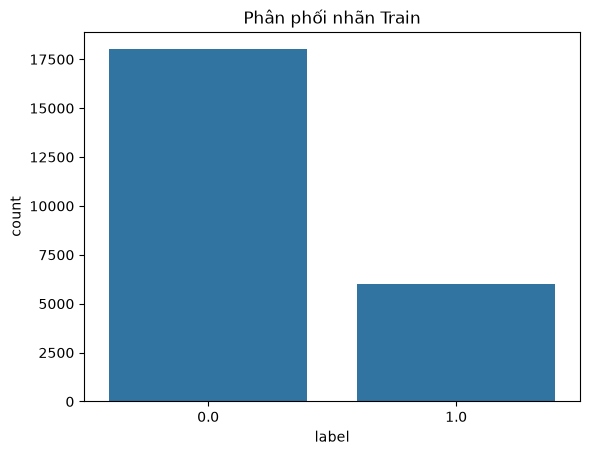

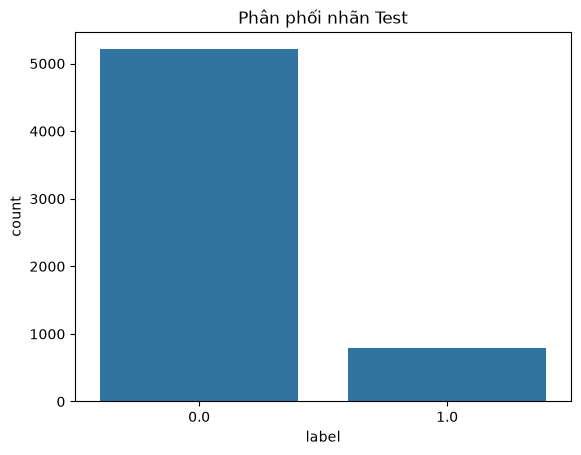

In [2]:
features = ["citation_velocity", "pagerank_score", "paper_age"]
target = "label"

train_full = df[df["temporal_split"] == "train"]
test_full = df[df["temporal_split"] == "test"]

train_1 = train_full[train_full[target] == 1].sample(n=6000, random_state=42)
train_0 = train_full[train_full[target] == 0].sample(n=18000, random_state=42)
train_balanced = pd.concat([train_1, train_0]).sample(frac=1.0, random_state=42)

test_sample = test_full.sample(n=6000, random_state=42)

X_train, y_train = train_balanced[features], train_balanced[target]
X_test, y_test = test_sample[features], test_sample[target]

print("Train shape (80%):", X_train.shape)
print("Test shape  (20%):", X_test.shape)
print("Tổng cộng:", len(X_train) + len(X_test), "records")

sns.countplot(x=y_train)
plt.title("Phân phối nhãn Train")
plt.show()

sns.countplot(x=y_test)
plt.title("Phân phối nhãn Test")
plt.show()

# 3. Định nghĩa Custom Metric cho dữ liệu lệch lớp


In [3]:
def f1_emerging(y_true, y_pred):
    return f1_score(y_true, y_pred, pos_label=1, zero_division=0)


# 4. Chạy LazyClassifier so sánh ~30 mô hình cùng lúc


In [4]:
clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=f1_emerging)
models, predictions = clf.fit(X_train, X_test, y_train, y_test)

models_sorted = models.sort_values(by="f1_emerging", ascending=False)
print(models_sorted)

                               Accuracy  Balanced Accuracy   ROC AUC  \
Model                                                                  
Perceptron                     0.851000           0.728954  0.791031   
SVC                            0.886167           0.689257  0.790728   
LabelPropagation               0.886000           0.689161  0.775897   
BernoulliNB                    0.886000           0.689161  0.689064   
AdaBoostClassifier             0.886000           0.689161  0.783065   
LogisticRegression             0.886000           0.689161  0.791029   
NearestCentroid                0.886000           0.689161  0.775896   
RandomForestClassifier         0.824000           0.726784  0.779251   
KNeighborsClassifier           0.797167           0.749334  0.781772   
BaggingClassifier              0.810500           0.729714  0.759955   
ExtraTreesClassifier           0.802333           0.728756  0.754328   
SGDClassifier                  0.887500           0.662189  0.77

# 5. Top 10 mô hình tốt nhất cho dữ liệu lệch lớp


In [5]:
models_sorted[["f1_emerging", "Balanced Accuracy", "ROC AUC", "Time Taken"]].head(10)

,f1_emerging,Balanced Accuracy,ROC AUC,Time Taken
Model,,,,
Perceptron,0.499440,0.728954,0.791031,0.015924
SVC,0.494449,0.689257,0.790728,2.848359
LabelPropagation,0.494083,0.689161,0.775897,5.359468
BernoulliNB,0.494083,0.689161,0.689064,0.015163
AdaBoostClassifier,0.494083,0.689161,0.783065,0.246002
LogisticRegression,0.494083,0.689161,0.791029,0.044598
NearestCentroid,0.494083,0.689161,0.775896,0.027778
RandomForestClassifier,0.471471,0.726784,0.779251,0.856662
KNeighborsClassifier,0.471100,0.749334,0.781772,0.043487
